# Speech → Indian Sign Language: a step-by-step walkthrough

**22AIE450 Speech Processing — project guide.** This notebook follows **one spoken sentence
through the whole system**, from the microphone to the sign videos, and runs the real project
code at every step, so each claim is shown, not just stated. (The longer report with the
literature review and theory is `Speech_to_ISL_Project.ipynb`.)

## The problem
Spoken English is everywhere — classrooms, announcements, offices — but India has millions of
Deaf people whose first language is **Indian Sign Language (ISL)**, not English. Human
interpreters are scarce. This project turns speech into ISL signs performed by real Deaf
signers, automatically.

## The pipeline
```
 microphone ─► 16 kHz audio ─► speech processing ─► speech recognition ─► text
   (browser)    (sampling)     (spectrogram, pitch,   (Whisper, fine-tuned    │
                                energy, ZCR, noise)    on Indian English)     │
                                                                              ▼
 sign videos ◄── order (spoken / ISL) ◄── sign lookup (laptop → Google Drive ◄─ text processing
 (ISLRTC, real     + question marking        → forms → synonyms → spell)       (numbers, omitted
  Deaf signers)                                                                  words, questions)
```

## What is our own work
| Part | Ours | Built on |
|---|---|---|
| Speech recognition | **fine-tuned Whisper on Indian-accented English (13.2 % → 11.3 % WER)** | OpenAI Whisper `base.en` |
| Speech processing | **pitch tracker, energy/ZCR, spectral subtraction, live display, noise & question studies** | numpy |
| Sign lookup | **dictionary builder, Drive on-demand fetch, word forms, reviewed synonyms, numbers, fingerspelling** | ISLRTC dictionary, WordNet |
| ISL output | **question detection, ISL word-order rules** | ISL grammar literature |

In [1]:
# Setup: load the project modules (the same code the web app runs).
import os, sys, time, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.getcwd())
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

from src import asr, matcher, isl_order, prosody, denoise, drive_fetch, fingerspell
from faster_whisper import decode_audio
print("project modules loaded")

project modules loaded


---
# Step 1 · The audio signal

**What happens.** The browser records the microphone and converts it to **16,000 samples per
second, mono, 16-bit** before sending it to the server.

**Why 16 kHz?** By the **Nyquist theorem** a sampling rate *fs* can represent frequencies up to
*fs/2*. Speech information (formants, fricatives like /s/, /f/) lies mostly below **8 kHz**, so
16 kHz keeps it all while using a third of the data of 48 kHz. Whisper is trained on 16 kHz.

**Why 16-bit?** Each sample is stored as one of 2¹⁶ = 65,536 levels; quantisation noise is about
**96 dB** below full scale — far below room noise.

Below: a real recording (the demo voice, recorded at 22,050 Hz) **resampled to 16 kHz** exactly
as the server does.

file as recorded : 22050 Hz, 1 channel, 16-bit, 4.55 s
after resampling : 16000 Hz, 72783 samples, 4.55 s, range -0.91 .. 0.96 (float32)
theoretical 16-bit dynamic range: 96 dB


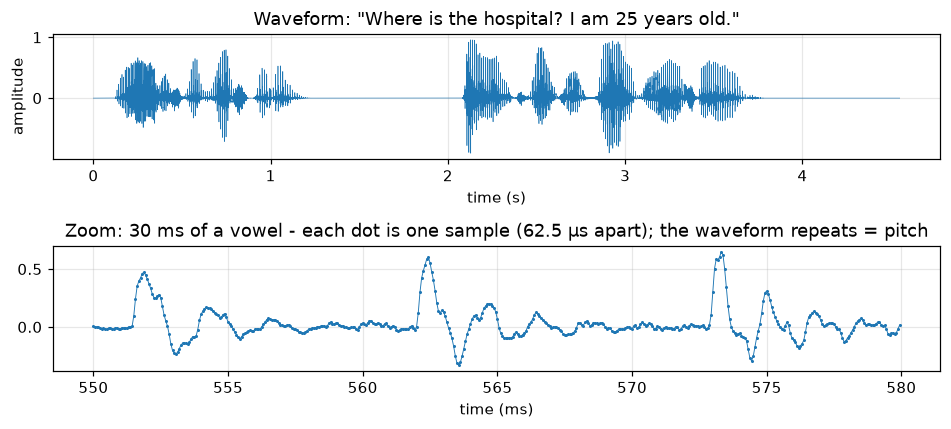

In [2]:
import wave
with wave.open("eval/demo_question.wav") as w:
    print(f"file as recorded : {w.getframerate()} Hz, {w.getnchannels()} channel, "
          f"{w.getsampwidth()*8}-bit, {w.getnframes()/w.getframerate():.2f} s")

x = decode_audio("eval/demo_question.wav", sampling_rate=16000)   # same call as the server
SR = 16000
print(f"after resampling : {SR} Hz, {len(x)} samples, {len(x)/SR:.2f} s, "
      f"range {x.min():.2f} .. {x.max():.2f} (float32)")
print(f"theoretical 16-bit dynamic range: {20*np.log10(2**16):.0f} dB")

fig, ax = plt.subplots(2, 1, figsize=(9, 4))
t = np.arange(len(x)) / SR
ax[0].plot(t, x, lw=0.4); ax[0].set_title("Waveform: \"Where is the hospital? I am 25 years old.\"")
ax[0].set_xlabel("time (s)"); ax[0].set_ylabel("amplitude")
zoom = slice(int(0.55*SR), int(0.58*SR))                      # 30 ms inside a vowel
ax[1].plot(t[zoom]*1000, x[zoom], ".-", ms=2, lw=0.6)
ax[1].set_title("Zoom: 30 ms of a vowel - each dot is one sample (62.5 µs apart); the waveform repeats = pitch")
ax[1].set_xlabel("time (ms)")
plt.tight_layout(); plt.show()

**Points to explain**
- The top plot shows **bursts (words) separated by pauses** — later steps detect these as
  voiced / silent.
- The zoom shows the waveform **repeating**: that period is the vocal folds opening and
  closing — the **pitch (F0)**, measured in Step 2.

---
# Step 2 · Speech processing: from samples to features

Speech changes every few milliseconds, but over **20–40 ms** it is roughly stable
(*short-time stationarity*). So all analysis is done on short **frames**.

## 2.1 Framing and windowing
Cut the signal into 25 ms frames every 10 ms (overlapping), and multiply each by a **Hann
window** so the frame edges fade to zero — otherwise the cut edges create false frequencies
(*spectral leakage*).

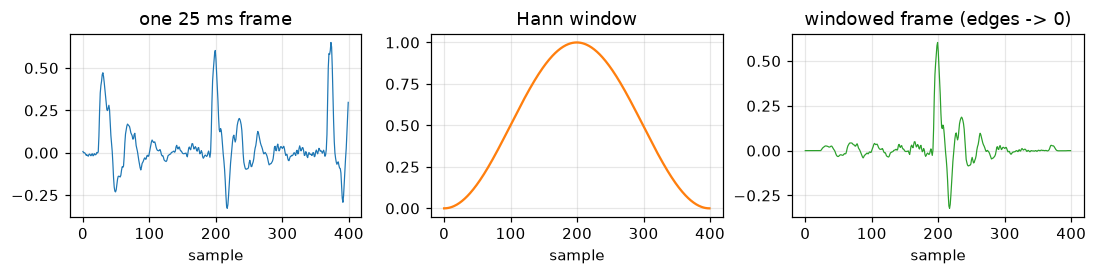

400 samples per frame, hop 160 -> 453 frames for 4.5 s of audio


In [3]:
FRAME, HOP = int(0.025*SR), int(0.010*SR)          # 400 samples, 160 samples
win = np.hanning(FRAME)
start = int(0.55*SR)
frame = x[start:start+FRAME]

fig, ax = plt.subplots(1, 3, figsize=(10, 2.6))
ax[0].plot(frame, lw=0.8); ax[0].set_title("one 25 ms frame")
ax[1].plot(win, color="tab:orange"); ax[1].set_title("Hann window")
ax[2].plot(frame*win, color="tab:green", lw=0.8); ax[2].set_title("windowed frame (edges -> 0)")
for a in ax: a.set_xlabel("sample")
plt.tight_layout(); plt.show()
n_frames = 1 + (len(x) - FRAME) // HOP
print(f"{FRAME} samples per frame, hop {HOP} -> {n_frames} frames for {len(x)/SR:.1f} s of audio")

## 2.2 Spectrum and spectrogram (STFT)
The **FFT** of each windowed frame gives its frequency content. Stacking the frames side by side
gives the **spectrogram**: time on x, frequency on y, energy as colour. Horizontal stripes in
vowels are **harmonics** (multiples of the pitch); dark bands are the **formants** that define
which vowel it is; noisy high-frequency patches are **fricatives** (/s/, /z/).

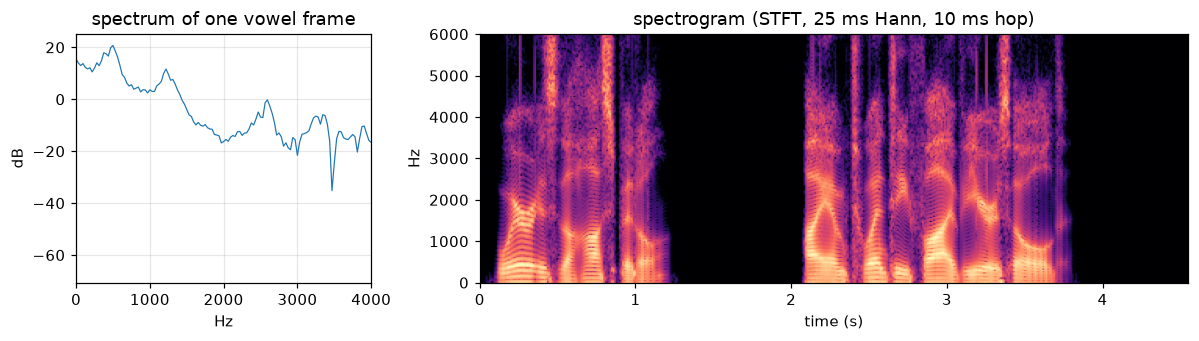

In [4]:
spec = np.abs(np.fft.rfft(frame*win, n=512))
freqs = np.fft.rfftfreq(512, 1/SR)

frames = np.stack([x[i*HOP:i*HOP+FRAME]*win for i in range(n_frames)])
S = 20*np.log10(np.abs(np.fft.rfft(frames, n=512, axis=1)).T + 1e-6)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2), gridspec_kw={"width_ratios": [1, 2.4]})
ax[0].plot(freqs, 20*np.log10(spec+1e-6), lw=0.8); ax[0].set_xlim(0, 4000)
ax[0].set_title("spectrum of one vowel frame"); ax[0].set_xlabel("Hz"); ax[0].set_ylabel("dB")
ax[1].imshow(S, origin="lower", aspect="auto", cmap="magma",
             extent=[0, len(x)/SR, 0, SR/2], vmin=S.max()-80, vmax=S.max())
ax[1].set_ylim(0, 6000); ax[1].set_title("spectrogram (STFT, 25 ms Hann, 10 ms hop)")
ax[1].set_xlabel("time (s)"); ax[1].set_ylabel("Hz"); ax[1].grid(False)
plt.tight_layout(); plt.show()

## 2.3 What Whisper actually receives: the log-mel spectrogram
Human hearing resolves low frequencies finely and high frequencies coarsely. The **mel scale**
models this: 80 triangular filters, narrow at low Hz and wide at high Hz, pool the spectrum into
80 bands; then the log compresses loudness the way the ear does. Whisper pads/crops every input
to **30 s** and computes an **80 × 3000** log-mel matrix (3000 frames = 30 s at 10 ms). The cell
below computes Whisper's *exact* input for our sentence.

Whisper input: 80 mel bands x 3000 frames (window 400 samples = 25 ms, hop 160 = 10 ms)


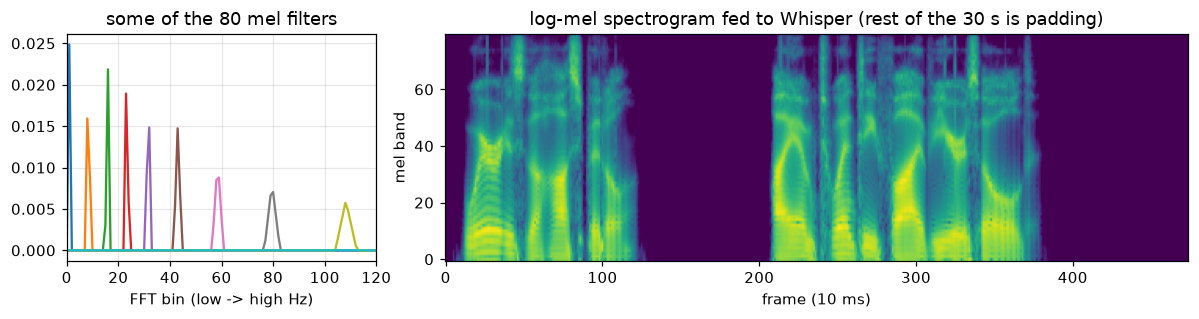

In [5]:
from transformers import WhisperFeatureExtractor
fe = WhisperFeatureExtractor.from_pretrained("models/whisper-base-en-svarah")
mel = fe(x, sampling_rate=SR, return_tensors="np").input_features[0]
print(f"Whisper input: {mel.shape[0]} mel bands x {mel.shape[1]} frames "
      f"(window {fe.n_fft} samples = {fe.n_fft/SR*1000:.0f} ms, hop {fe.hop_length} = {fe.hop_length/SR*1000:.0f} ms)")

used = int(len(x)/SR*100) + 20
fig, ax = plt.subplots(1, 2, figsize=(11, 3), gridspec_kw={"width_ratios": [1, 2.4]})
ax[0].plot(fe.mel_filters[:, ::8]); ax[0].set_xlim(0, 120)
ax[0].set_title("some of the 80 mel filters"); ax[0].set_xlabel("FFT bin (low -> high Hz)")
ax[1].imshow(mel[:, :used], origin="lower", aspect="auto", cmap="viridis")
ax[1].set_title("log-mel spectrogram fed to Whisper (rest of the 30 s is padding)")
ax[1].set_xlabel("frame (10 ms)"); ax[1].set_ylabel("mel band"); ax[1].grid(False)
plt.tight_layout(); plt.show()

## 2.4 Short-time energy and zero-crossing rate (time-domain features)
- **Energy** (in dB) per frame: high for speech, low for silence → a simple **voice activity
  detector**.
- **Zero-crossing rate (ZCR)**: how often the waveform crosses zero. Voiced sounds (vowels) are
  low-frequency, few crossings; unvoiced sounds (/s/, /f/) are noise-like, many crossings.

## 2.5 Pitch (F0) — our autocorrelation tracker
For a voiced frame, compare the signal with **shifted copies of itself**; the shift (lag) with
the best match is one pitch period, so **F0 = sample rate / lag**. We search 70–400 Hz (human
voice range) and call a frame voiced if the match (normalised autocorrelation) is ≥ 0.5.
**Octave-error guard:** multiples of the period match almost as well, so we take the *shortest*
strong peak — without it a 330 Hz voice was read as 82.5 Hz in testing. The same algorithm runs
live in the web page while you speak.

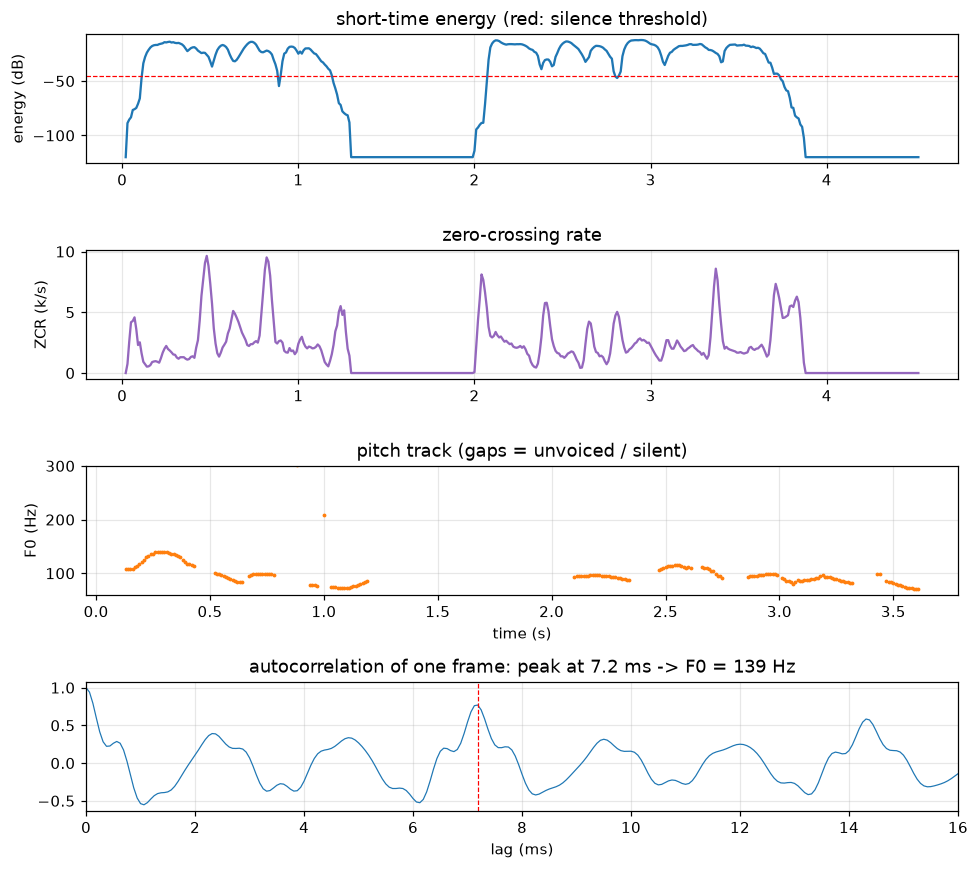

voiced frames 43% | median F0 95 Hz (male voice range ~85-180 Hz)
mean ZCR: voiced 1954/s  vs  unvoiced-but-loud 4085/s


In [6]:
times, f0 = prosody.f0_track(x)                       # the project's tracker (src/prosody.py)
fr = np.stack([x[i*prosody.HOP:i*prosody.HOP+prosody.FRAME] for i in range(len(times))])
energy = 10*np.log10(np.mean(fr**2, axis=1) + 1e-12)
zcr = np.mean(np.abs(np.diff(np.sign(fr), axis=1)) > 0, axis=1) * SR

# autocorrelation of one voiced frame, to show where the pitch comes from
voiced_idx = np.where(~np.isnan(f0))[0]
k = voiced_idx[np.argmin(np.abs(times[voiced_idx] - 0.30))]   # a clear vowel inside "Where"
seg = fr[k] - fr[k].mean()
ac = np.correlate(seg, seg, "full")[len(seg)-1:]; ac /= ac[0]
lags = np.arange(len(ac))

fig, ax = plt.subplots(4, 1, figsize=(9, 8), sharex=False)
ax[0].plot(times, energy); ax[0].axhline(prosody.SILENCE_DB, ls="--", c="r", lw=0.8)
ax[0].set_ylabel("energy (dB)"); ax[0].set_title("short-time energy (red: silence threshold)")
ax[1].plot(times, zcr/1000, c="tab:purple"); ax[1].set_ylabel("ZCR (k/s)"); ax[1].set_title("zero-crossing rate")
ax[2].plot(times, f0, ".", ms=3, c="tab:orange"); ax[2].set_ylim(60, 300)
ax[2].set_ylabel("F0 (Hz)"); ax[2].set_xlabel("time (s)"); ax[2].set_title("pitch track (gaps = unvoiced / silent)")
ax[3].plot(lags/SR*1000, ac, lw=0.8); ax[3].set_xlim(0, 16)
best = SR / f0[k]
ax[3].axvline(best/SR*1000, c="r", ls="--", lw=0.8)
ax[3].set_title(f"autocorrelation of one frame: peak at {best/SR*1000:.1f} ms -> F0 = {f0[k]:.0f} Hz")
ax[3].set_xlabel("lag (ms)")
plt.tight_layout(); plt.show()

voiced = ~np.isnan(f0)
loud = energy > prosody.SILENCE_DB
print(f"voiced frames {voiced.mean()*100:.0f}% | median F0 {np.nanmedian(f0):.0f} Hz (male voice range ~85-180 Hz)")
print(f"mean ZCR: voiced {zcr[voiced].mean():.0f}/s  vs  unvoiced-but-loud {zcr[loud & ~voiced].mean():.0f}/s")

**Points to explain**
- Energy separates speech from silence; ZCR is higher for unvoiced sounds — exactly the
  time-domain theory.
- The pitch contour moves over the sentence; at the end of a statement it usually **falls**.
- The autocorrelation plot shows *why* the method works: the signal matches itself best one
  period later.

---
# Step 3 · Noise and spectral subtraction

Real rooms are noisy. **Spectral subtraction** (Boll, 1979) is the classic fix, implemented by
us in `src/denoise.py`:
1. STFT of the noisy signal.
2. Estimate the noise spectrum from the **quietest 10 % of frames**.
3. Subtract it (×2 over-subtraction), keeping a small floor so no bin goes negative (limits
   "musical noise").
4. Inverse STFT using the noisy phase.

SNR: noisy 5.0 dB  ->  after spectral subtraction 11.3 dB


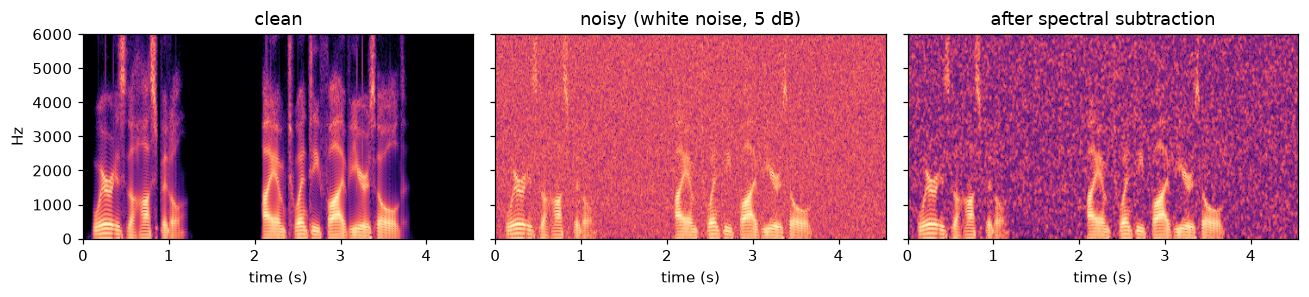

In [7]:
rng = np.random.default_rng(0)
noise = rng.standard_normal(len(x)).astype(np.float32)
noise *= np.sqrt(np.mean(x**2) / (np.mean(noise**2) * 10**(5/10)))   # 5 dB SNR
noisy = x + noise
clean_est = denoise.spectral_subtract(noisy)
print(f"SNR: noisy {denoise.snr_db(x, noisy):.1f} dB  ->  after spectral subtraction "
      f"{denoise.snr_db(x, clean_est):.1f} dB")

def spg(sig):
    f = np.stack([sig[i*HOP:i*HOP+FRAME]*win for i in range(n_frames)])
    return 20*np.log10(np.abs(np.fft.rfft(f, n=512, axis=1)).T + 1e-6)
fig, ax = plt.subplots(1, 3, figsize=(12, 2.8), sharey=True)
for a, sig, title in zip(ax, [x, noisy, clean_est], ["clean", "noisy (white noise, 5 dB)", "after spectral subtraction"]):
    Sx = spg(sig); a.imshow(Sx, origin="lower", aspect="auto", cmap="magma", extent=[0, len(x)/SR, 0, SR/2],
                            vmin=S.max()-80, vmax=S.max())
    a.set_ylim(0, 6000); a.set_title(title); a.set_xlabel("time (s)"); a.grid(False)
ax[0].set_ylabel("Hz"); plt.tight_layout(); plt.show()

**But does it help speech recognition?** We measured it (`tools/noise_study.py`): 200 recordings
from 16 unseen speakers × white and babble (crowd) noise × 20 / 10 / 5 / 0 dB × two models, with
and without spectral subtraction — 7,200 transcriptions.

In [8]:
import csv
rows = list(csv.DictReader(open("eval/noise_study.csv", encoding="utf-8")))
def wer(m, n, s, d):
    return next(100*float(r["wer"]) for r in rows if r["model"] == m and r["noise"] == n
                and r["snr_db"] == s and r["denoise"] == str(d))
print(f"{'condition':<15}{'stock':>8}{'+SS':>8}{'ours':>8}{'+SS':>8}   (WER %, SS = spectral subtraction)")
for n, s in [("clean", ""), ("white", "10"), ("white", "5"), ("babble", "10"), ("babble", "5")]:
    vals = [wer(m, n, s, d) for m in ("base.en", "whisper-base-en-svarah") for d in (0, 1)]
    print(f"{n + (' ' + s + ' dB' if s else ''):<15}" + "".join(f"{v:7.1f} " for v in vals))

condition         stock     +SS    ours     +SS   (WER %, SS = spectral subtraction)
clean             13.1    13.6    11.0    11.9 
white 10 dB       28.3    28.8    25.4    24.5 
white 5 dB        44.9    43.9    34.5    36.5 
babble 10 dB      22.2    25.8    21.1    21.3 
babble 5 dB       41.5    47.4    36.8    39.8 


**Points to explain (two findings)**
1. Spectral subtraction **raises SNR** but makes Whisper **slightly worse** in 15 of 18
   conditions: Whisper was trained on noisy audio and is confused more by the subtraction's
   artefacts than by the noise. So it is a switch in the app, **off by default**.
2. Our **fine-tuned model is more robust to noise** (white 5 dB: 44.9 % → 34.5 % WER) although
   it never trained on noise.

---
# Step 4 · Speech recognition: Whisper, fine-tuned by us

## How Whisper works
An **encoder–decoder Transformer**. The **encoder** reads the 80 × 3000 log-mel matrix from
Step 2.3 and builds an internal representation of the audio. The **decoder** writes the text
one token at a time, attending to the encoder output (cross-attention) and to the words it has
already written. We use greedy decoding (most likely token each step) for speed.

## Why we fine-tuned it
Stock Whisper learned mostly from Western-accented English and makes more errors on Indian
speakers. Training from scratch is impossible (Whisper used 680,000 hours), so we **fine-tuned**
it — continued training — on **Svarah**, an Indian-accented English dataset (AI4Bharat).

Live inference below: the same sentences through the stock model and our model, on the GPU.

In [9]:
from faster_whisper import WhisperModel
asr._register_pip_cuda_libs()
import ctranslate2
dev = "cuda" if ctranslate2.get_cuda_device_count() else "cpu"
ctype = "float16" if dev == "cuda" else "int8"
models = {"stock base.en": WhisperModel("base.en", device=dev, compute_type=ctype),
          "ours (fine-tuned)": WhisperModel("models/whisper-base-en-svarah", device=dev, compute_type=ctype)}
print("device:", dev.upper())
for wav in ["eval/sample.wav", "eval/demo_question.wav"]:
    audio = decode_audio(wav, sampling_rate=16000)
    print(f"\n{wav}")
    for name, m in models.items():
        list(m.transcribe(audio[:16000], language="en", beam_size=1)[0])      # warm-up
        t0 = time.perf_counter()
        segs, _ = m.transcribe(audio, language="en", beam_size=1, initial_prompt="Mothishwaran")
        text = " ".join(s.text.strip() for s in segs)
        print(f"  {name:18} {int((time.perf_counter()-t0)*1000):4d} ms  {text}")

device: CUDA

eval/sample.wav


  stock base.en       129 ms  Hello, thank you. My name is Mothishwaran.


  ours (fine-tuned)    77 ms  Hello, thank you. My name is Mothishwaran

eval/demo_question.wav


  stock base.en        79 ms  Where is the hospital? I am 25 years old.
  ours (fine-tuned)    69 ms  Where is the hospital? I am 25 years old


## The training, in four facts
1. **Data:** Svarah — 6,656 utterances, 9.6 h, 117 speakers from across India.
2. **Fair split:** by **speaker** — 84 train / 15 dev / 16 test, so the test voices were never
   heard in training. (Svarah's file names look like speaker ids but are not; we caught that
   before training — otherwise test speakers would have leaked into training.)
3. **Training:** 3 epochs, batch 16, learning rate 1e-5, on our RTX 4050 laptop GPU, 69 minutes;
   checkpoints every 200 steps; the best dev checkpoint was exported (76 MB) and is committed.
4. **Result:** below.

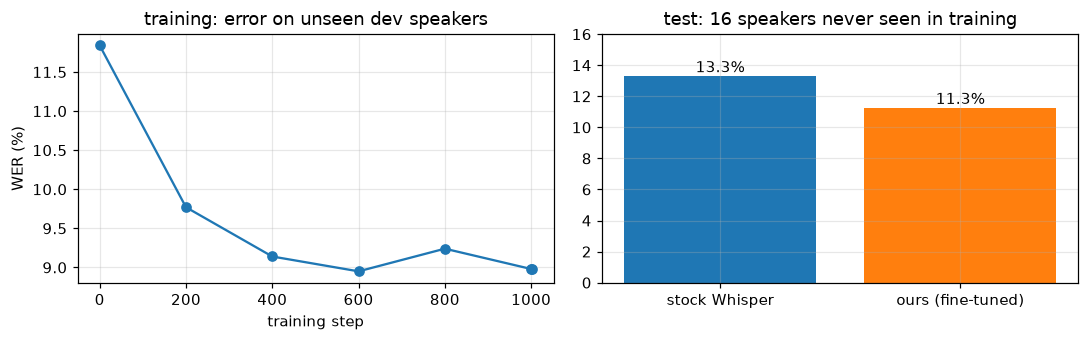

word error rate: stock 13.32%  ->  ours 11.27%  (15% fewer errors); 14 of 16 speakers improved; significant in 2000/2000 bootstrap resamples


In [10]:
import csv
log = list(csv.DictReader(open("eval/train_log_base_en_svarah.csv", encoding="utf-8")))
st = [int(r["step"]) for r in log if r["dev_wer"]]; dv = [100*float(r["dev_wer"]) for r in log if r["dev_wer"]]

hyps = list(csv.DictReader(open("eval/asr_svarah_test_hyps.csv", encoding="utf-8")))
import jiwer
from tools.train.metrics import normalize
def corpus_wer(model):
    pairs = [(normalize(r["reference"]), normalize(r["hypothesis"])) for r in hyps if r["model"] == model]
    pairs = [p for p in pairs if p[0].strip()]
    return 100*jiwer.wer([a for a, _ in pairs], [b for _, b in pairs])
stock, ours = corpus_wer("base.en"), corpus_wer("whisper-base-en-svarah")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(st, dv, "o-"); ax[0].set_title("training: error on unseen dev speakers")
ax[0].set_xlabel("training step"); ax[0].set_ylabel("WER (%)")
bars = ax[1].bar(["stock Whisper", "ours (fine-tuned)"], [stock, ours], color=["tab:blue", "tab:orange"])
ax[1].bar_label(bars, fmt="%.1f%%"); ax[1].set_ylim(0, 16)
ax[1].set_title("test: 16 speakers never seen in training")
plt.tight_layout(); plt.show()
print(f"word error rate: stock {stock:.2f}%  ->  ours {ours:.2f}%  ({(stock-ours)/stock*100:.0f}% fewer errors); "
      f"14 of 16 speakers improved; significant in 2000/2000 bootstrap resamples")

**Points to explain**
- **WER** = (substituted + deleted + inserted words) ÷ words in the reference.
- The dev curve falls then flattens; we kept the best point (step 600) — that is *early
  stopping*, which avoids overfitting.
- Known limits: very short phrases ("cricket match") fail for every model — there is no
  context — so the app has a **correction box** to type the right text.

---
# Step 5 · Text processing

The transcript is split into words, lower-cased, punctuation removed (apostrophes kept:
*don't*). Then:
- **Numbers** are read as spoken: *25* → TWENTY FIVE, *7:30* → SEVEN THIRTY (digit by digit
  when a word like *forty* has no sign).
- **Words ISL does not sign** — *a, an, the, is, am, are, to, of* — are marked **omitted**: ISL
  has no articles and no "to be" ("Where is the hospital?" is signed HOSPITAL WHERE).
- **Question detection** uses word order (question word first, verb first, or "?"). Pitch is
  measured as evidence; our study on 774 real recordings showed that in read Indian English,
  yes/no questions don't rise — they fall less — so pitch alone was only 66.5 % accurate and is
  not used to decide.

In [11]:
text = models["ours (fine-tuned)"].transcribe(x, language="en", beam_size=1, initial_prompt="Mothishwaran")[0]
text = " ".join(s.text.strip() for s in text)
print("transcript   :", text)
print("normalised   :", matcher.normalize_phrase(text))
print("number '25'  :", matcher.number_signs("25", matcher._load_manifest()))
print("number '7:30':", matcher.number_signs("7:30", matcher._load_manifest()))
print("number '45'  :", matcher.number_signs("45", matcher._load_manifest()), " (no sign for 'forty' -> digits)")
plan = matcher.match(text, spell_unknown=True)["plan"]
q = isl_order.detect_question(text, plan)
pitch = prosody.final_rise(x)
print(f"\nquestion     : {q['type']}  ({q['evidence']})")
print(f"final pitch  : {pitch['final_rise_st']:+.1f} semitones (falling = statement-like), median F0 {pitch['median_f0']:.0f} Hz")

transcript   : Where is the hospital? I am 25 years old
normalised   : where is the hospital i am 25 years old
number '25'  : ['twenty', 'five']
number '7:30': ['seven', 'thirty']
number '45'  : ['four', 'five']  (no sign for 'forty' -> digits)

question     : wh  (sentence 1: starts with "where")
final pitch  : -3.5 semitones (falling = statement-like), median F0 95 Hz


---
# Step 6 · Finding the signs

The signs are **real videos of Deaf signers** from the official ISLRTC dictionary — ~4,000
phrases on the laptop plus ~2,700 more on the ISLRTC Google Drive. Each word goes through this
chain; the first step that works wins:

| # | Step | Example |
|---|---|---|
| 1 | longest phrase **on the laptop** | *thank you* = one sign, not two |
| 2 | else the phrase **on Google Drive** — downloaded once, then cached | *parrot* ☁ |
| 3 | a **number** | *25* → TWENTY FIVE |
| 4 | a capitalised name → **fingerspell** | *Mothishwaran* |
| 5 | an **omitted** word (not signed in ISL) | *is, the* |
| 6 | an **inflected form** of a dictionary word | *went* → GO |
| 7 | a **reviewed synonym** | *physician* → DOCTOR |
| 8 | otherwise **fingerspell** it letter by letter | *about* → A-B-O-U-T |

Synonyms come from **WordNet** and were reviewed by hand, because we found that AI "similarity"
is unsafe: it matched *Monday → Tuesday* and *husband → wife*.

In [12]:
def show(sentence):
    m = matcher.match(sentence, spell_unknown=True)
    mark = {"sign": "[{}]", "similar": "{{{}}}", "related": "<{}>", "spell": "spell:{}", "omitted": "({})", "uncovered": "_{}_"}
    parts = []
    for p in m["plan"]:
        label = p["token"] + (f"->{p['means']}" if p.get("means") and p["means"] != p["token"].lower() else "")
        label += " ☁drive" if "drive" in p else ""
        parts.append(mark[p["type"]].format(label))
    print(f"{sentence:45} {' '.join(parts)}")

print("[sign]  {synonym}  spell:fingerspelled  (omitted)  ☁ = not on laptop, would be fetched from Drive\n")
for s in ["Hello, thank you. My name is Mothishwaran.",
          "We went to the market yesterday.",
          "The physician told me to rest.",
          "My parrot and my rabbit.",
          "How about you, my boy?",
          "I am 25 years old."]:
    show(s)

cat = matcher._load_remote()
everyday = [w for w in ["mango", "banana", "ambulance", "rainbow", "pilot", "snake", "crocodile",
                        "hockey", "balloon", "helicopter", "pumpkin", "candle", "spoon"] if w in cat]
print(f"\nDrive catalogue: {len(cat)} more signs fetchable on demand, e.g. {', '.join(everyday)} ...")

[sign]  {synonym}  spell:fingerspelled  (omitted)  ☁ = not on laptop, would be fetched from Drive

Hello, thank you. My name is Mothishwaran.    [hello] [thank you] [my name is] spell:Mothishwaran
We went to the market yesterday.              [we] [went->go] (to) (the) [market] [yesterday]
The physician told me to rest.                (The) {physician->doctor} spell:told spell:me (to) [rest]
My parrot and my rabbit.                      [my] [parrot] spell:and [my] spell:rabbit
How about you, my boy?                        spell:How spell:about [you] [my] [boy]
I am 25 years old.                            _I_ (am) [25->twenty five] [years->year] [old]

Drive catalogue: 2740 more signs fetchable on demand, e.g. mango, banana, ambulance, rainbow, pilot, snake, crocodile, hockey, balloon, helicopter, pumpkin, candle, spoon ...


**Points to explain**
- ☁ words are not on the laptop: the server downloads only that one video from Google Drive
  (~3–6 s the first time), checks it is a real sign (≤ 30 s), and caches it.
- *rabbit*, *how*, *about* are nowhere in the 15,462-video Drive, so they are **fingerspelled**
  — exactly what a Deaf signer does for a word without a sign.

---
# Step 7 · Sign order: spoken order or ISL order

By default signs play **in the order spoken**. With the **ISL word order** switch on, three
safe ISL grammar rules apply inside each sentence: **time words first**, **negation last**,
**question word last**. Full subject–object–verb order is not attempted: a wrong reorder is
worse than none.

In [13]:
for s in ["Where is the hospital?", "I go to school tomorrow.", "I never eat rice.", "Can you help me tomorrow?"]:
    m = matcher.match(s, spell_unknown=True)
    spoken = isl_order.gloss(m["plan"], list(range(len(m["plan"]))))
    order, rules = isl_order.reorder(m["plan"])
    q = isl_order.detect_question(s, m["plan"])
    print(f"{s:28} spoken: {spoken:28} ISL: {isl_order.gloss(m['plan'], order):28} {('[' + q['type'] + ' question]') if q['type'] else ''}")

Where is the hospital?       spoken: WHERE HOSPITAL               ISL: HOSPITAL WHERE               [wh question]
I go to school tomorrow.     spoken: GO SCHOOL TOMORROW           ISL: TOMORROW GO SCHOOL           
I never eat rice.            spoken: NEVER EAT RICE               ISL: EAT RICE NEVER               
Can you help me tomorrow?    spoken: CAN YOU HELP M-E TOMORROW    ISL: TOMORROW CAN YOU HELP M-E    [yesno question]


A **yes/no question** in ISL is marked with **raised eyebrows** — a facial expression. Isolated
dictionary clips cannot show it, so the app labels the question instead of faking it.

---
# Step 8 · The output: sign videos

Below: the middle frame of each clip the app would play for our sentence, in order —
dictionary signs, the number as two signs, and fingerspelled letters for a name.

Where is the hospital? I am 25 years old. My name is Ravi.
plays as: WHERE HOSPITAL TWENTY FIVE YEAR OLD MY NAME IS R-A-V-I


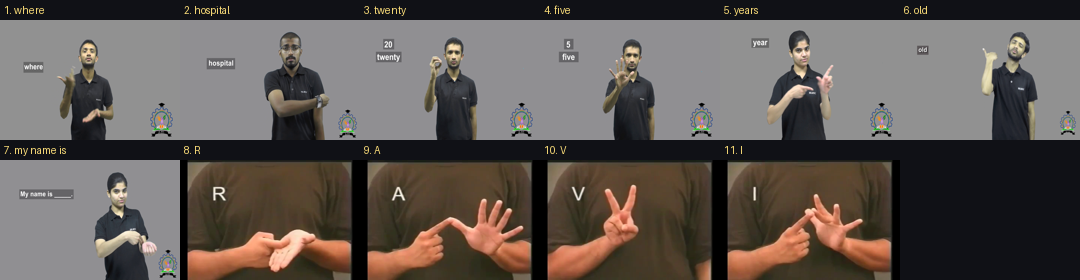

In [14]:
import av
from PIL import Image, ImageDraw

def middle_frame(path):
    c = av.open(path); v = c.streams.video[0]
    frames = [f for f in c.decode(v)]; c.close()
    return frames[len(frames)//2].to_image()

sentence = "Where is the hospital? I am 25 years old. My name is Ravi."
m = matcher.match(sentence, spell_unknown=True)
tiles = []
for p in m["plan"]:
    for i, clip in enumerate(p["clips"]):
        label = p.get("means", p["token"]).split()[i] if p.get("means") and len(p["clips"]) > 1 else p["token"]
        if p["type"] == "spell":
            label = os.path.splitext(os.path.basename(clip))[0].upper()
        if "drive" in p:
            continue                                  # not downloaded in this notebook
        tiles.append((label, middle_frame(clip)))

W, H, COLS = 180, 120, 6
rows_n = (len(tiles) + COLS - 1) // COLS
sheet = Image.new("RGB", (COLS*W, rows_n*(H+20)), (16, 17, 22))
d = ImageDraw.Draw(sheet)
for i, (label, img) in enumerate(tiles):
    xx, yy = (i % COLS)*W, (i // COLS)*(H+20)
    sheet.paste(img.resize((W, H)), (xx, yy+20))
    d.text((xx+4, yy+4), f"{i+1}. {label}", fill=(250, 220, 120))
print(sentence)
print("plays as:", isl_order.gloss(m["plan"], list(range(len(m["plan"])))))
display(sheet)

**Points to explain**
- Every sign is a **real Deaf signer** from the ISLRTC dictionary — no avatars, no AI-generated
  signs (studies show Deaf users rate avatars poorly, and generated signs are not valid ISL).
- In the app, clips play back-to-back with two video players swapping, so there is no black gap.

---
# Step 9 · Results summary

In [15]:
import csv, json, statistics
def cov(path):
    sents = [l.strip() for l in open(path, encoding="utf-8") if l.strip()]
    ms = [matcher.match(s) for s in sents]
    return [100*statistics.mean(m[k] for m in ms) for k in ("coverage", "content_coverage", "content_coverage_with_similar")]
held = cov("eval/test_sentences_heldout.txt")
q = json.load(open("eval/question_threshold.json"))
rows = [
    ("Speech recognition WER, 16 unseen speakers", f"stock {stock:.1f}%  ->  ours {ours:.1f}%"),
    ("Speakers improved by fine-tuning", "14 of 16 (bootstrap 2000/2000)"),
    ("Noise robustness, white noise 5 dB", "stock 44.9%  ->  ours 34.5% WER"),
    ("Spectral subtraction", "+4 to +7 dB SNR, but WER worse in 15/18 conditions"),
    ("Pitch alone as question cue", f"{q['heldout_dev_test']['balanced_acc']*100:.1f}% balanced accuracy"),
    ("Question detection (word order + '?')", "93% of questions, 1/70 false alarms"),
    ("Sign coverage, 20 fresh sentences", f"{held[0]:.0f}% all words, {held[1]:.0f}% of words ISL signs, {held[2]:.0f}% with synonyms"),
    ("Dictionary", f"{len(matcher._load_manifest())} phrases local + {len(matcher._load_remote())} via Drive"),
    ("Speed", "speech recognition ~0.2-0.4 s on the laptop GPU"),
]
for k, v in rows:
    print(f"{k:42} {v}")

Speech recognition WER, 16 unseen speakers stock 13.3%  ->  ours 11.3%
Speakers improved by fine-tuning           14 of 16 (bootstrap 2000/2000)
Noise robustness, white noise 5 dB         stock 44.9%  ->  ours 34.5% WER
Spectral subtraction                       +4 to +7 dB SNR, but WER worse in 15/18 conditions
Pitch alone as question cue                66.5% balanced accuracy
Question detection (word order + '?')      93% of questions, 1/70 false alarms
Sign coverage, 20 fresh sentences          55% all words, 67% of words ISL signs, 72% with synonyms
Dictionary                                 4068 phrases local + 2740 via Drive
Speed                                      speech recognition ~0.2-0.4 s on the laptop GPU


---
# Step 10 · Limitations, future work and viva points

## What the system does not do (say this first)
- It **retrieves real signs; it is not full translation**. Word order is spoken order unless
  the ISL switch is on, and only three ISL rules are applied.
- **No facial expressions** (non-manual markers), which carry part of ISL grammar.
- **Not yet evaluated with Deaf users** — we measured accuracy and coverage, not understanding.
- Very short phrases with no context are misheard; the correction box handles it honestly.

## Future work
1. Evaluation with Deaf ISL users.
2. Fine-tune on more Indian speech, including noise (our study shows noise is the weak point).
3. Richer ISL grammar using a parallel corpus such as ISLTranslate.

## Likely viva questions → the key point to make
| Question | Key point |
|---|---|
| Why 16 kHz? | Nyquist: speech info < 8 kHz; Whisper is trained at 16 kHz |
| Why frame the signal? | Speech is only stationary over ~20–40 ms |
| What does Whisper see? | 80-band log-mel spectrogram, 30 s window |
| How does your pitch tracker work? | Autocorrelation peak = period; F0 = fs / lag; shortest strong peak avoids octave errors |
| Why is ZCR higher for unvoiced sounds? | They are noise-like, high-frequency |
| Did you train anything? | Yes — fine-tuned Whisper on Svarah; 13.2 % → 11.3 % WER on unseen speakers |
| How do you know it isn't luck? | Speaker-disjoint test; 14/16 speakers improved; bootstrap 2000/2000 |
| Why didn't spectral subtraction help? | Whisper is trained on noisy audio; subtraction artefacts hurt more than the noise |
| Why not use pitch for questions? | In this data yes/no questions don't rise; word order is far more reliable |
| Why real videos, not an avatar? | Deaf users prefer human signers; generated signs aren't valid ISL |
| What if a word has no sign? | Drive → synonym → fingerspell, as signers do |